# 주장과 근거의 관계

개선안의 한 문장은 무엇이 문제다 주장이 있고, 그 증거로 이런 숫자가 있다 근거로 구성되어있다. 근거가 왜 주장을 뒷받침하는지에 대한 설명이 있어야하고, 이 설명을 연결고리 라고 일컫는다.

데이터: 부산항만공사 선박 입출항집계, 해양수산부 선박관제정보
- 주장: 통제 해제 직후 관제의 입항 순서 지정 업무가 몰린다.
- 연결고리: 뒷받침 근거 데이터 입항 한건 -> 관제가 순서를 지정한 입항 건수
- 근거: 통제가 해제된 다음 날 가장 바쁜 한시간 입항 척수는 13척이었고, 평소에는 10척정도였다.

같은 근거가 어떤 주장은 잘 뒷받침하고, 어떤 주장은 전혀 뒷받침하지 못할 수 있다.

- 근거: 통제 해제 직후 들어온 컨테이너선의 항해시간이 직전 기간보다 17.6시간 길다.

- 주장: 통제 기간중에서는 바다에서 기다린 선박이 섞여있다.
- 연결고리: 항해 시간에는 부산항 앞 대기가 섞여 있다.

- 주장: 입항 순서를 미리 정하면 선박 대기가 줄어든다.
- 연결고리: 순서를 미리 정하면 대기의 총량이 줄어든다.

## 근거 매트릭스

근거 매트릭스 하나의 근거가 여러 주장을 뒷받침하기도 하고, 어떤 주장은 근거가 없기도 한데, 이러한 관계를 행열로 표현해놓은것을 의미한다. 주장이 행이되고, 근거가 열로 구성되어있다.



In [ ]:
!uv add pandas numpy matplotlib

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False # 한글폰트에서 -표시 깨짐방지

In [10]:
from matplotlib.colors import ListedColormap

claims = [ 'A1', 'A2', 'A3', 'B1', 'B2', 'D1' ]
# Q는 정량, S는 정성 근거
evidence_ids = [ 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'S1', 'S2', 'S3' ]

links = [
    ( 'A1', 'Q1', 1 ), ( 'A1', 'Q2', 1 ), ( 'A1', 'S1', 1 ),
    ( 'A2', 'Q3', 1 ),
    ( 'A3', 'Q4', -1 ), ( 'A3', 'Q5', -1 ), ( 'A3', 'S2', 1 ),
    ( 'B1', 'Q6', 1 ), ( 'B1', 'S3', 1 ),
    ( 'B2', 'S3', 1 ),
    ( 'D1', 'Q7', 1 ),
]

matrix = pd.DataFrame(0, index=claims, columns=evidence_ids)

for claim, ev, sign in links:
    matrix.loc[claim, ev] = sign

print(matrix.shape, (matrix != 0).sum().sum())

(6, 10) 11


In [11]:
cmap = ListedColormap(['#c8553d', 'white', '#3d7cc8'])

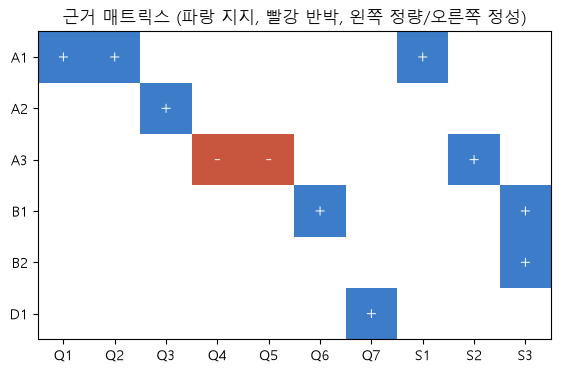

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix.iloc[i, j]
        if value:
            ax.text(j, i, "+" if value > 0 else "-", ha="center", va="center", fontsize=13, color="white")

ax.set_xticks(range(len(evidence_ids)), evidence_ids)
ax.set_yticks(range(len(claims)), claims)

ax.set_title('근거 매트릭스 (파랑 지지, 빨강 반박, 왼쪽 정량/오른쪽 정성)')

plt.show()

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load_dataset(filename, cols=None):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding='euc-kr', usecols=cols if cols else None)

## 입출항 집계

In [40]:
d004 = load_dataset('입출항', ['입항일시'])

d004['입항'] = pd.to_datetime(d004['입항일시'], format='%Y-%m-%d %H:%M', errors='coerce')
d004 = d004[d004['입항'].dt.year.between(2019, 2024)]

print(len(d004))

272861


## 관제정보

In [50]:
d012 = load_dataset('선박관제정보', cols=['관제항구', '입항일시', '상태구분'])
d012 = d012[(d012['관제항구'] == '부산') & (d012['상태구분'] != '삭제')]

d012['입항'] = pd.to_datetime(d012['입항일시'], errors='coerce')

d012.head()


,관제항구,입항일시,상태구분,입항
0,부산,2024-05-01 01:10:00,수정,2024-05-01 01:10:00
4,부산,2024-05-01 03:00:00,수정,2024-05-01 03:00:00
6,부산,2024-05-01 09:00:00,수정,2024-05-01 09:00:00
8,부산,2024-05-01 07:35:00,수정,2024-05-01 07:35:00
13,부산,2024-05-01 08:35:00,수정,2024-05-01 08:35:00


In [49]:
d012.info()

<class 'pandas.DataFrame'>
Index: 41936 entries, 0 to 176737
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   관제항구    41936 non-null  str           
 1   입항일시    41936 non-null  str           
 2   상태구분    41936 non-null  str           
 3   입항      41936 non-null  datetime64[us]
dtypes: datetime64[us](1), str(3)
memory usage: 1.6 MB


In [51]:
print(len(d012), d012['입항'].min().date(), d012['입항'].max().date())

41936 2024-05-01 2025-07-31


In [53]:
# 기대선 대비 비율
# 그날 입항 / 직전달 28일 중앙값

daily_004 = d004['입항'].dt.normalize().value_counts().sort_index().asfreq('D', fill_value=0)
daily_012 = d012['입항'].dt.normalize().value_counts().sort_index().asfreq('D', fill_value=0)
daily_012

입항
2024-05-01     90
2024-05-02     98
2024-05-03    104
2024-05-04    110
2024-05-05     62
             ... 
2025-07-27     80
2025-07-28    103
2025-07-29    104
2025-07-30     71
2025-07-31     29
Freq: D, Name: count, Length: 457, dtype: int64

In [55]:
overlap = pd.date_range('2024-05-01', '2024-12-31')

overlap

DatetimeIndex(['2024-05-01', '2024-05-02', '2024-05-03', '2024-05-04',
               '2024-05-05', '2024-05-06', '2024-05-07', '2024-05-08',
               '2024-05-09', '2024-05-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[us]', length=245, freq='D')

In [56]:
both = pd.DataFrame({
    'D004': daily_004.reindex(overlap),
    'D012': daily_012.reindex(overlap, fill_value=0),
})

both

,D004,D012
2024-05-01,108,90
2024-05-02,128,98
2024-05-03,153,104
2024-05-04,156,110
2024-05-05,79,62
...,...,...
2024-12-27,133,89
2024-12-28,119,88
2024-12-29,112,93
2024-12-30,139,97


In [62]:
# 기대선 대비 비율
# 그날 입항 / 직전달 28일 중앙값

ratio_004 = daily_004 / daily_004.shift(1).rolling(28).median()
ratio_012 = daily_012 / daily_012.shift(1).rolling(28).median()

# ratio_004['2024-10-20']
round(ratio_012['2024-10-20'], 2)

np.float64(0.31)

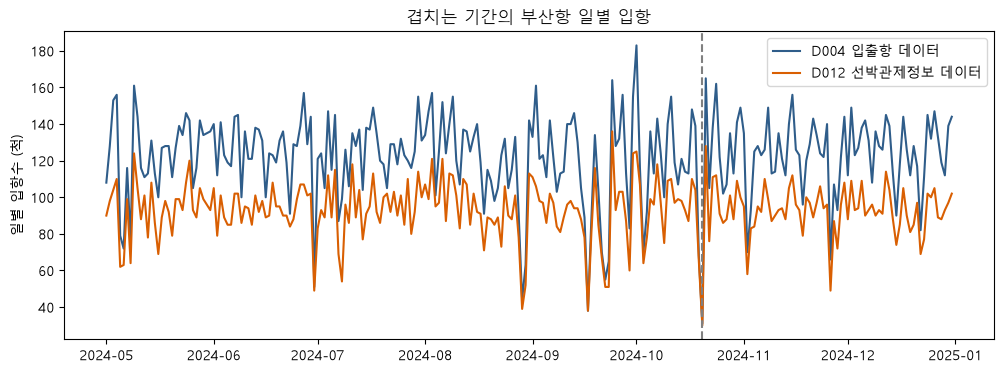

In [68]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(both.index, both['D004'], color='#2f5d8a' , label='D004 입출항 데이터')
ax.plot(both.index, both['D012'], color='#d95f02', label='D012 선박관제정보 데이터')

ax.axvline(pd.Timestamp('2024-10-20'), color='gray', linestyle='--')

ax.set_ylabel('일별 입항수 (척)')
ax.set_title('겹치는 기간의 부산항 일별 입항')

ax.legend()

plt.show()

In [69]:
level_ratio = (both['D012'] / both['D004']).median()

round(level_ratio, 2)

np.float64(0.76)

In [73]:
corr_level = both['D004'].corr(both['D012'])

In [76]:
corr_diff = both['D004'].diff().corr(both['D012'].diff())

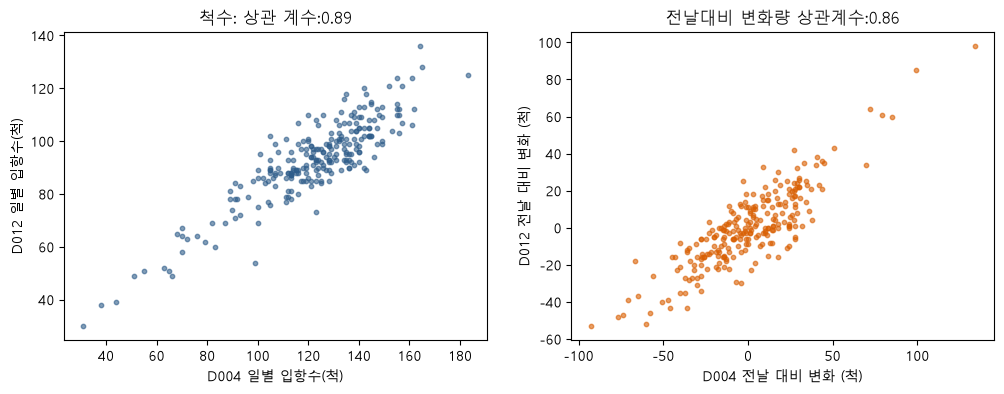

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(both['D004'], both['D012'], s=10, alpha=0.6, color='#2f5d8a')
axes[0].set_xlabel('D004 일별 입항수(척)')
axes[0].set_ylabel('D012 일별 입항수(척)')

axes[0].set_title(f'척수: 상관 계수:{corr_level:.2f}')

axes[1].scatter(both['D004'].diff(), both['D012'].diff(), s=10, alpha=0.6, color='#d95f02')
axes[1].set_xlabel('D004 전날 대비 변화 (척)')
axes[1].set_ylabel('D012 전날 대비 변화 (척)')

axes[1].set_title(f'전날대비 변화량 상관계수:{corr_diff:.2f}')


plt.show()

In [83]:
change = both.diff().dropna()
mismatch = np.sign(change['D004']) != np.sign(change['D012'])

print(round(mismatch.mean() * 100, 1))

big_change = change['D004'].abs() > 30

print(big_change.sum())

22.5
52


# 근거(Evidence)

근거는 주장이 옳다고 믿을 이유를 제공하는 사실이다. 개선안에서는 근거가 중요하다. 개선안을 읽는 사람이 대개 해당 업무를 직접적으로 분석하지 않은 사람이기 때문이다.

'분석가가 알고있는 사실, 알고있다' 문서 안에서 다른사람이 확인할 수 있는 형태 및 근거를 제시할 수 있어야 된다.

## 주장, 근거, 연결고리

내일 오후에 비가 온다.는 주장이다. 서쪽에서 저기압이 다가오고 있다.는 근거이다.
저기압이 다가오면 대개 비가온다 라는 일반 원리가 하나 숨어있다.

근거가 왜 주장을 뒷받침하는지 설명하는 숨은 전제를 연결고리라고 일컫는다.

```text
- 주장: 월요일 오전 신고 처리 담당자의 업무가 주말 입항분으로 밀린다.

- 근거: 허가의 34.3%가 월요일에 기록됨. 월요일 허가의 65.5%가 금~일요일 입항에서 비롯됨

- 연결고리: 허가일자는 담당자가 신고를 처리한 시각이다.
```

- 주장: 선박이 주말에 기다린다.
- 근거: 허가의 34.3%가 월요일에 처리된다.
- 연결고리: 허가가 있어야만 선박이 움직일수 있다.
  - 허가가 출항 예정보다도 늦게 기록된 입항이 88%가 넘는다.

## 근거 카드

근거를 수치 하나만 적어두면 나중에 다시 찾거나 검증하기 어려울 수 있다.

- 내용: 수치나 인용문 자체
- 단위/정의: 무엇을 어떻게 측정했는가
- 기준 기간: 언제의 값인가
- 비교 기준: 무엇과 비교하여 크기가 작은가
- 출처: 어느 데이터/누구의 말인가
- 가공방법: 어떤 행을 빼고 어떻게 계산했는가

`허가의 34.3%가 월요일에 처리된다.` 평소 수준 주말 제외하고 주일(월~금) 공평하게 나눠서 분배하면 20%, 14.3%

## 정량 근거(Quantitative Evidence)

정량 근거는 측정한 값으로 구성되어있는 근거를 의미한다. 정량 근거가 설명할수 있는(뒷받침하는) 내용은 크기와 범위이다.

- 월요일에 일이 몰려요.
- 허가 5만 3천 여건 가운데 34.3%인 약 1만8천건정도가 월요일에 처리돼요.

KPI는 상태를 요약한 값이고, 근거는 특정 주장을 뒷받침하는 값이다.
같은 KPI라도 어떤 주장 옆에 놓이느냐에 따라서 강한 근거가 될수도 있고 아무런 관계 없는 그냥 지표가 될수도 있다.

KPI를 근거로 바꾸는 단계, 비율의 분모를 다루는 방법, 대리지표의 주의점

### KPI를 근거로 변환

온도계가 38.5도를 나타내고 있다.

체온일 경우, 정상 체온이 36.5도 안팎이기 때문에 현재 온도계가 나타내고있는 값이 높은편이고, 열이 있다 가 성립될 수 있다.

3일동안 온도계가 38.x도를 가리키고 있다.

KPI를 근거로 바꾸려면 `값 -> 비교 -> 해석`의 과정이 있어야 한다.

- 값: 지표를 계산
- 비교: 기준선, 다른집단, 다른 기간이랑 비교
- 해석: 비교 결과가 어떤 주장을 뒷받침하는지 연결고리를 찾는다

- 값: '24 풀컨테이너선 동시 체류 척수 평균 37.4척
- 비교: 95번째 백분위수 46척, 최대 62척('24-02-17, 설 연휴 직후)
- 해석: 명절 직후 수일간 컨테이너 부두 혼잡이 평소의 1.3~1.7배정도 커진다.

비교기준같은 경우에는 주장에 맞게 선택해야 한다.

기준선 비교는 같은 대상의 과거값이나 평균값과 비교하는 것이기 때문에 평소보다 나빠졌다 라는 주장에는 어울린다. 집단비교를 하면 외항, 내항, 주말입항, 평일입항처럼 다른 집단이랑 비교하는것이기때문에 특정 집단에서 문제가 크다 라는 주장에 어울린다. 목표비교는 정해둔 목표값과 현재값을 비교하는 것이기 때문에 목표에 미치지 못한다 라는 주장에 어울린다.

### 분모 선택

비율로 되어있는 근거는 분모에따라서 전혀 다른이야기를 할 수 있다.

- 연결되지 않은 입항 15000건 가운데 내항이 14990건이다
- 내항 입항의 관제연결률이 40.6%이다.

대표값, 기간 선택도 분모와 함께 확인해야할 중요한 요소이다. 체류시간 꼬리가 길어서, 평균이 소수의 극단값에 끌려다닌다.

개선효과를 말할때 평균을 쓰면 극단값 몇건만 줄어도 큰 개선처럼 보일 수 있고, 중앙값을 쓰면 대부분의 선박이 겪는 변화가 드러날수 있다.

- 비율 = 해당 건수 / 분모 건수 * 100
- 기준 대비 배수 =  관측 비율 /  기준 비율 (1보다 큰경우 기준보다 몰림현상)
- 집단간 차이(%p) = 집단 A의 비율 - 집단 B의 비율

### 직접 지표와 대리 지표

확인하려는 현상을 그대로 측정한 값을 직접 지표(Direct Indicator)라고 일컫는다.
현상을 직접적으로 측정할 수 없거나 해서 관련된 다른 값으로 그 값을 대체한 지표를 대리 지표(Proxy Indicator)라고 일컫는다.

공공데이터를 이용할경우에는 대리지표를 쓸 경우가 상대적으로 많다.

- 박지 입항 비율: 선박 대기의 대리지표
- xx 허가 일자: 처리 담당자 업무 시각의 대리지표

대리지표는 사용을 지양해야하는 지표가 아니라, 사용하되 대리지표라고 밝히고 사용해야 한다.

대리지표
해당 지표는 xx을 대리하기 위한 지표

- 허가일자는 담당자가 실제로 신고를 검토한 시각이 아니라 시스템에 허가가 확정된 시각일 수도 있기 때문에, 월요일 몰림이 담당자의 업무 부담인지,  단순히 확정 버튼을 누르는 시각의 몰림인지는 정확히 구분하기 어렵다. 이러한 대리지표는 정성 근거로 근거를 채워야 한다.

## 정성 근거(Qualitative Evidence)

정성 근거는 사람의 말, 관찰 기록, 문서처럼 수치로 요약되지 않는 자료에서 나오는 근거를 의미한다. 정량근거는 얼마나, 어디서를 의미하고, 정성 근거는 왜, 어떻게를 의미한다.

월요일에 허가가 몰린다는 사실은 알 수 있었다. 주말에 담당자가 없는것인지, 주말에 처리는 됐는데 월요일에 실제 허가가 떨어진건지는 알 수 없다. 따라서 '왜'에 해당되는 부분은 정성 근거로 채워야 한다.

정성 근거는 수치가 없기때문에 약한 근거가 아닌가 하는 생각을 할 수 있다. 그러나 역할이 다르다라고 접근하는 것이 옳다. 원인 가설, 연결고리, 현장 제약처럼 데이터에 흔ㄴ적이 남지 않는 내용을 정성근거 없이는 채울수 없기 때문이다.

### 정성 근거의 종류

- 인터뷰: 담당자에게 '정해진 질문'으로 묻는것
- 현장 관찰: 실제 업무를 옆에서 보고 기록하는 것
- 문서/규정: 규정, 메뉴얼, 데이터 명세를 확인하는 것
- 이용자 의견: 민원, 설문, 게시판 의견을 모으는 것

- 강/약점
  - 인터뷰: 원인/맥락/예외를 확인 가능하다. 말하는 사람에 기억에 좌우된다.
  - 현장관찰: 말과 실제 행동의 차이를 볼 수있다. 시간이 들고 관찰 기간이 짧다.
  - 문서/규정: 공식 기준이기때문에 논란의 여지가 적다. 현장이 규정대로 일한다는 보장 없다.
  - 이용자 의견: 많은 사람의 불편(Pain)을 넓게 확인 가능하다. 불만이 큰 사람의 목소리가 과대 대표된다.

## 코딩(Coding)

분류번호와 같이 정성 자료의 문장마다 이 문장은 어떤주제에 대한 의견인가를 나타내는 짧은 이름표를 붙이는 작업을 수행하고 이를 코딩이라고 한다.




## 정량 근거와 정성 근거를 연결

정량 근거와 정성근거를 수집했으면 두 근거를 하나의 주장으로 모을수 있어야된다.

근거의 갯수를 증폭시키기 위함이 아니라 한 종류의 근거가 증명하지 못하는 다른 부분을 다른 종류로 채우고, 두 근거가 서로를 검증하게 하기 위함이다.

### 역할분담

정량 근거와 정성 근거는 서로 다른 질문에 대답하고 있다. 정량근거 무엇이, 얼마나, 어디서 일어나고있는지에 대한 내용을 답하고, 정성근거는 왜, 어떻게, 누구에게 어떤의미로 일어나는지를 답한다.

개선안의 문장 구성 항목에 대응해보면 현재상태, 기대효과는 주로 정량근거가 사용되고, 원인 가설, 실행 조건은 주로 정성근거가 채워준다.

- 설명적 순서: 데이터에서 먼저 이상한 모습을 찾고 그 이유를 현장에 물어보는방법
- 탐색적 순서: 현장의 이야기를 먼저 듣고나서 그 이야기가 얼마나 넓게 적용되는지를 데이터로 확인하는 방법

```
- 설명적 순서(정량 -> 정성)
  - 데이터: 허가 34.3%가 월요일 -> 인터뷰: 왜 월요일에 몰려요? -> 원인 가설 확정 수정

- 탐색적 순서(정성 -> 정량)
  - 인터뷰: 출항 예정이 자꾸 바뀐다 -> 데이터: 출항 예정 변경이 몇 %입항에서 일어나는가 -> 문제의 크기를 확정할 수 있다.
```

정량 근거만으로만 멈추게되면 원인 가설이 짐작으로 채워지게되고, 정성 근거만으로 멈추면 기대효과가 누락되고 숫자의 근거가 없어진다.

